<a href="https://colab.research.google.com/github/nurfahdilla293/praktikum_evaluasi_model.ipynb/blob/main/Praktikum_9_Ensemble_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Machine Learning — Bab 9
## Ensemble Learning: Random Forest, Bagging, dan Boosting


## 1. Perhitungan OOB
Pada bootstrap, peluang satu data **tidak terpilih** adalah (1 − 1/n)ⁿ. Untuk n besar, nilainya mendekati e⁻¹ ≈ 0,3679.

In [14]:
import numpy as np

for n in [10, 100, 1000, 100000]:
    print(f"n = {n:>6} -> (1 - 1/n)^n = {(1 - 1/n)**n:.4f}")
print("e^-1            =", round(np.exp(-1), 4))

n =     10 -> (1 - 1/n)^n = 0.3487
n =    100 -> (1 - 1/n)^n = 0.3660
n =   1000 -> (1 - 1/n)^n = 0.3677
n = 100000 -> (1 - 1/n)^n = 0.3679
e^-1            = 0.3679


**Interpretasi:** Sekitar **36,8%** data tidak terpilih pada tiap bootstrap sample, sehingga jadi data *out-of-bag* (OOB). Data ini dipakai untuk menguji pohon tersebut, jadi OOB error bisa dipakai sebagai estimasi validasi tanpa cross-validation.


### Praktikum 9.1 Persiapan Library

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.ensemble import (RandomForestClassifier,
                              GradientBoostingClassifier, AdaBoostClassifier)
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

### Praktikum 9.2 Import Dataset

In [16]:
data = load_wine(as_frame=True)
X, y = data.data, data.target
print("Ukuran data:", X.shape)
print("Jumlah per kelas:", y.value_counts().sort_index().to_dict())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)

Ukuran data: (178, 13)
Jumlah per kelas: {0: 59, 1: 71, 2: 48}
Data latih: (142, 13) | Data uji: (36, 13)


### Praktikum 9.3 Preprocessing dan Training Model

In [29]:
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=42)
rf.fit(X_train, y_train)

ada = AdaBoostClassifier(n_estimators=100, random_state=42)
ada.fit(X_train, y_train)

gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
gb.fit(X_train, y_train)

tree_tunggal = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

### Praktikum 9.4 Evaluasi

In [18]:
print("OOB Score Random Forest:", round(rf.oob_score_, 3))
print()

hasil = []
for nama, model in [("Decision Tree Tunggal", tree_tunggal),
                    ("Random Forest", rf),
                    ("AdaBoost", ada),
                    ("Gradient Boosting", gb)]:
    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    f1 = f1_score(y_test, pred, average="macro")
    print(f"{nama}: Akurasi Test = {acc:.3f} | F1 macro = {f1:.3f}")
    hasil.append({"Model": nama, "Akurasi": round(acc, 3), "F1 macro": round(f1, 3)})

pd.DataFrame(hasil).set_index("Model")

OOB Score Random Forest: 0.979

Decision Tree Tunggal: Akurasi Test = 0.944 | F1 macro = 0.946
Random Forest: Akurasi Test = 1.000 | F1 macro = 1.000
AdaBoost: Akurasi Test = 0.917 | F1 macro = 0.920
Gradient Boosting: Akurasi Test = 0.944 | F1 macro = 0.945


,Akurasi,F1 macro
Model,,
Decision Tree Tunggal,0.944,0.946
Random Forest,1.000,1.000
AdaBoost,0.917,0.920
Gradient Boosting,0.944,0.945


### Praktikum 9.5 Visualisasi Feature Importance

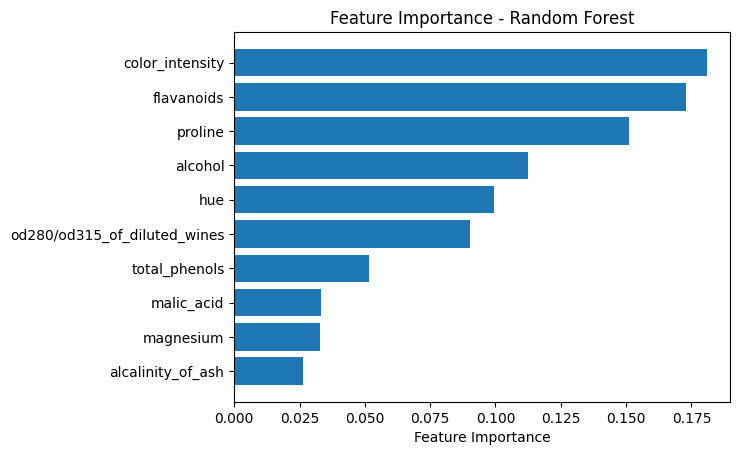

In [19]:
importances = rf.feature_importances_
idx = np.argsort(importances)[::-1][:10]

plt.barh([data.feature_names[i] for i in idx][::-1],
         importances[idx][::-1])
plt.xlabel("Feature Importance")
plt.title("Feature Importance - Random Forest")
plt.show()

### Interpretasi Praktikum 9.1–9.5
- **Random Forest** paling baik: akurasi test 1,000 dan OOB score 0,979. Nilai OOB yang tinggi dan stabil menunjukkan model tidak overfitting.
- **Decision Tree tunggal** dan **Gradient Boosting** sama-sama 0,944, sedangkan **AdaBoost** 0,917. Ketiganya lebih rendah dari Random Forest.
- Data uji hanya 36 sampel, jadi selisih kecil bisa saja kebetulan. Karena itu perbandingan di Latihan 2 (cross-validation) lebih dapat dipercaya.
- Fitur paling penting: `color_intensity`, `flavanoids`, dan `proline`. Ketiganya paling banyak mengurangi impurity saat pohon bercabang.

## 3. Latihan Praktikum 1: Pengaruh `n_estimators`
**Tujuan:** Melihat pengaruh jumlah pohon terhadap OOB score dan akurasi test Random Forest.

In [20]:
rows = []
for n in [10, 50, 100, 300, 500]:
    model = RandomForestClassifier(n_estimators=n, oob_score=True, random_state=42)
    model.fit(X_train, y_train)
    acc = accuracy_score(y_test, model.predict(X_test))
    print(f"n_estimators={n}: OOB={model.oob_score_:.3f}, Test Acc={acc:.3f}")
    rows.append({"n_estimators": n, "OOB Score": model.oob_score_, "Test Acc": acc})

tabel_n = pd.DataFrame(rows).set_index("n_estimators").round(3)
tabel_n

n_estimators=10: OOB=0.951, Test Acc=1.000
n_estimators=50: OOB=0.972, Test Acc=1.000
n_estimators=100: OOB=0.979, Test Acc=1.000
n_estimators=300: OOB=0.979, Test Acc=1.000
n_estimators=500: OOB=0.979, Test Acc=1.000


,OOB Score,Test Acc
n_estimators,,
10,0.951,1.0
50,0.972,1.0
100,0.979,1.0
300,0.979,1.0
500,0.979,1.0


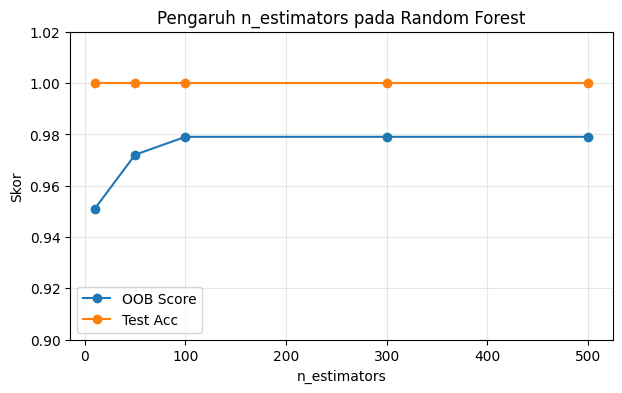

In [21]:
tabel_n.plot(marker="o", figsize=(7, 4))
plt.ylim(0.9, 1.02)
plt.xlabel("n_estimators"); plt.ylabel("Skor")
plt.title("Pengaruh n_estimators pada Random Forest")
plt.grid(alpha=0.3)
plt.show()

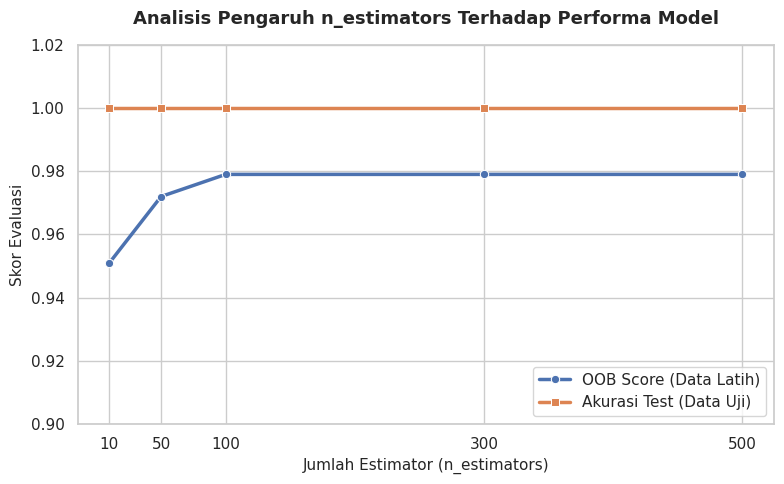

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")

# Memplot OOB Score dan Test Acc menggunakan data dari tabel_n
sns.lineplot(data=tabel_n, x="n_estimators", y="OOB Score", marker="o", linewidth=2.5, label="OOB Score (Data Latih)")
sns.lineplot(data=tabel_n, x="n_estimators", y="Test Acc", marker="s", linewidth=2.5, label="Akurasi Test (Data Uji)")

plt.ylim(0.90, 1.02)
plt.title("Analisis Pengaruh n_estimators Terhadap Performa Model", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Jumlah Estimator (n_estimators)", fontsize=11)
plt.ylabel("Skor Evaluasi", fontsize=11)
plt.xticks(tabel_n.index)
plt.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.show()

### Visualisasi Salah Satu Pohon dari Random Forest
Untuk memahami bagaimana Random Forest mengambil keputusan, mari kita visualisasikan salah satu pohon keputusan individu (`estimators_[0]`) dari model Random Forest yang telah kita latih.

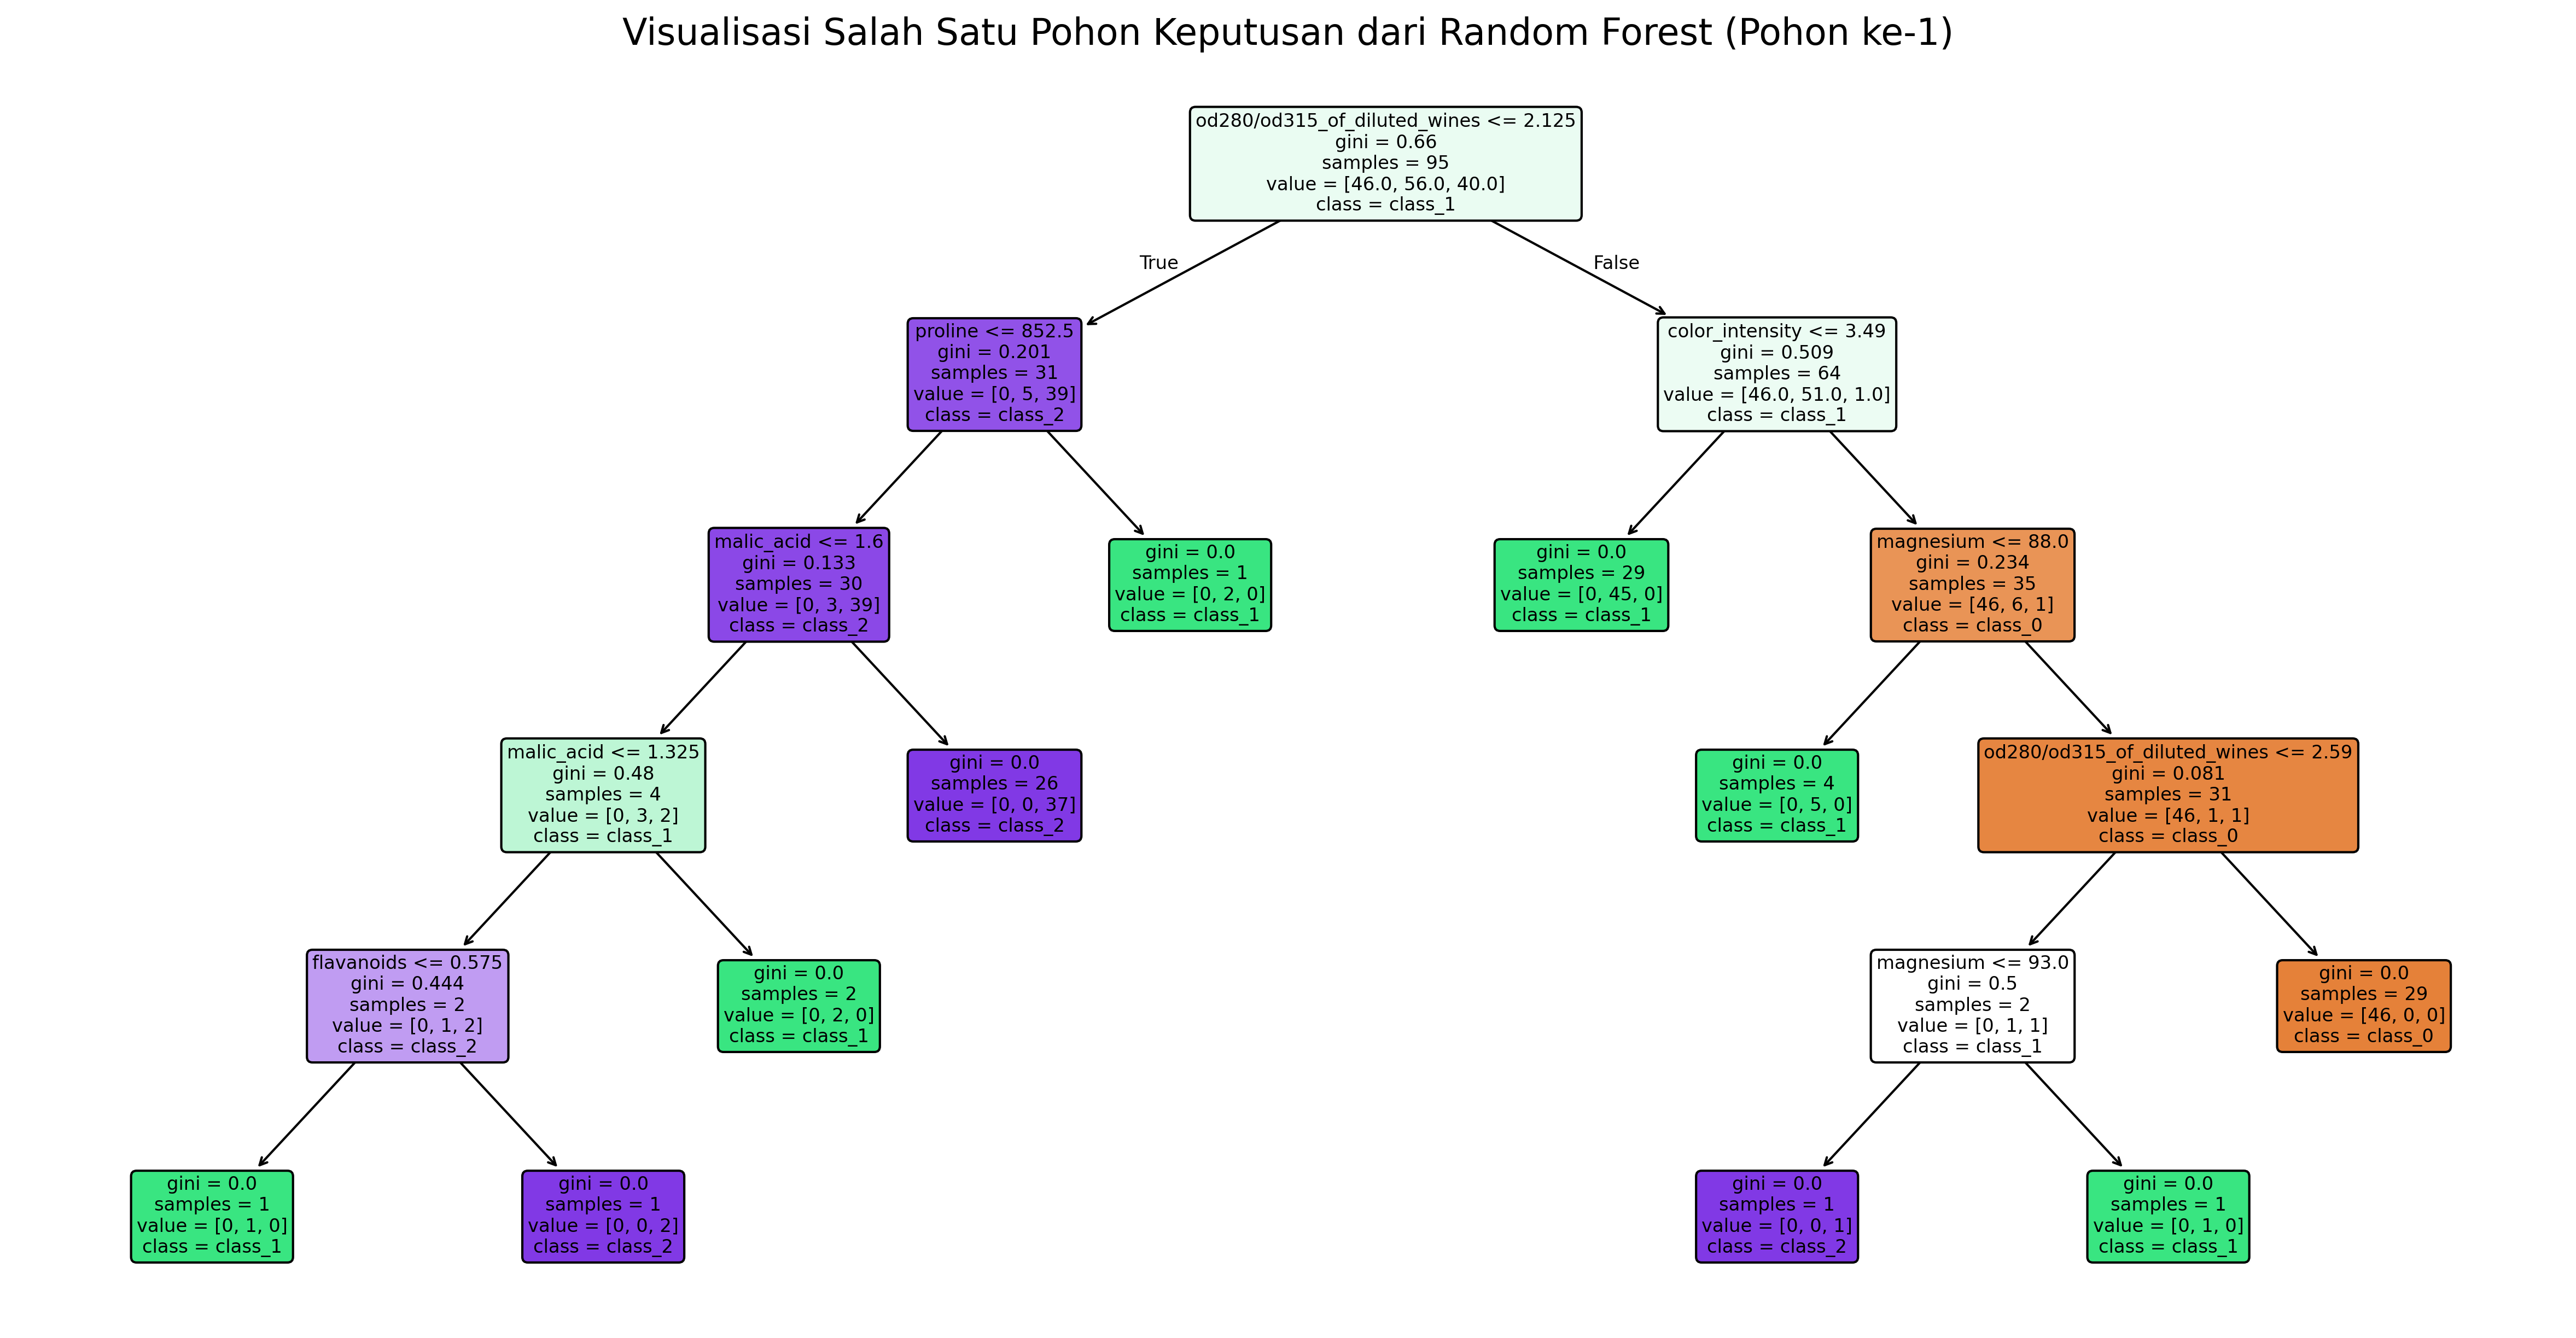

In [22]:
from sklearn.tree import plot_tree

# Mengambil pohon pertama dari random forest (rf)
pohon_tunggal = rf.estimators_[0]

# Melakukan visualisasi pohon keputusan
plt.figure(figsize=(20, 10), dpi=300)
plot_tree(pohon_tunggal,
          feature_names=data.feature_names,
          class_names=data.target_names,
          filled=True,
          rounded=True)
plt.title("Visualisasi Salah Satu Pohon Keputusan dari Random Forest (Pohon ke-1)", fontsize=16)
plt.show()

**Analisis:**  
OOB score naik dari 0,951 (10 pohon) ke 0,972 (50 pohon) lalu 0,979 (100 pohon), dan **stabil** di 0,979 sampai 300 dan 500 pohon. Artinya menambah pohon membantu di awal, tapi setelah sekitar 100 pohon hasilnya tidak naik lagi dan hanya menambah waktu komputasi. Akurasi test sudah 1,000 sejak 10 pohon karena data uji kecil. Menambah pohon tidak membuat Random Forest overfitting.

## 4. Latihan Praktikum 2: Perbandingan Empat Model
**Tujuan:** Membandingkan Decision Tree, Random Forest, AdaBoost, dan Gradient Boosting dengan Stratified K-Fold CV.

**Instruksi:** `StratifiedKFold(n_splits=5)` dan `cross_val_score` dengan `scoring="f1_macro"`. Sajikan hasil dalam tabel dan tulis kesimpulan model terbaik.

In [23]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Decision Tree":     DecisionTreeClassifier(random_state=42),
    "Random Forest":     RandomForestClassifier(n_estimators=300, random_state=42),
    "AdaBoost":          AdaBoostClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42),
}

rows = []
for nama, model in models.items():
    skor = cross_val_score(model, X, y, cv=skf, scoring="f1_macro")
    rows.append({"Model": nama,
                 "F1 macro (mean)": round(skor.mean(), 3),
                 "Std": round(skor.std(), 3),
                 "Mean ± Std": f"{skor.mean():.3f} ± {skor.std():.3f}"})

tabel_cv = pd.DataFrame(rows).set_index("Model").sort_values("F1 macro (mean)", ascending=False)
tabel_cv

,F1 macro (mean),Std,Mean ± Std
Model,,,
Random Forest,0.984,0.021,0.984 ± 0.021
AdaBoost,0.929,0.044,0.929 ± 0.044
Gradient Boosting,0.924,0.030,0.924 ± 0.030
Decision Tree,0.896,0.036,0.896 ± 0.036


### Visualisasi Perbandingan Performa Model (Bar Chart)
Berikut adalah grafik perbandingan nilai rata-rata F1-Score Macro dari hasil Stratified 5-Fold Cross Validation untuk masing-masing model.

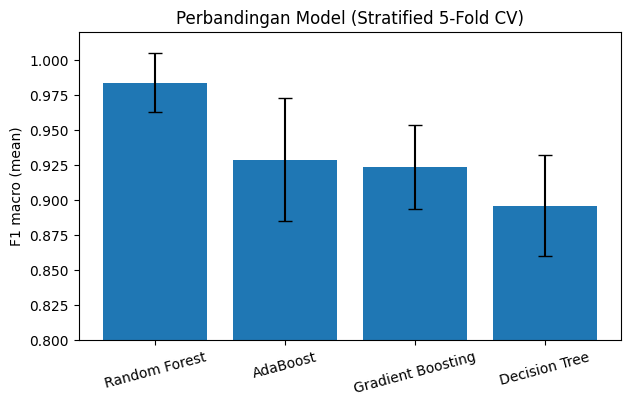

In [24]:
plt.figure(figsize=(7, 4))
plt.bar(tabel_cv.index, tabel_cv["F1 macro (mean)"], yerr=tabel_cv["Std"], capsize=5)
plt.ylim(0.8, 1.02)
plt.ylabel("F1 macro (mean)")
plt.title("Perbandingan Model (Stratified 5-Fold CV)")
plt.xticks(rotation=15)
plt.show()

In [25]:
display(tabel_cv)

,F1 macro (mean),Std,Mean ± Std
Model,,,
Random Forest,0.984,0.021,0.984 ± 0.021
AdaBoost,0.929,0.044,0.929 ± 0.044
Gradient Boosting,0.924,0.030,0.924 ± 0.030
Decision Tree,0.896,0.036,0.896 ± 0.036


**Kesimpulan Latihan 2:**  
**Random Forest** adalah model terbaik dengan F1 macro **0,984 ± 0,021**, dan simpangan bakunya paling kecil sehingga paling stabil. Disusul AdaBoost (0,929) dan Gradient Boosting (0,924), sedangkan Decision Tree tunggal paling rendah (0,896). Ini sesuai materi: bagging mengurangi *variance* pohon tunggal, sedangkan boosting lebih sensitif terhadap noise dan perlu tuning. Pada dataset wine yang kecil dan bersih, Random Forest paling cocok.

## 5. Kesimpulan
Ensemble menggabungkan banyak model agar prediksi lebih akurat dan stabil dibanding satu model. Pada dataset wine, **Random Forest** terbaik (F1 CV 0,984, OOB 0,979) dan hasilnya stabil setelah sekitar 100 pohon. Boosting (AdaBoost dan Gradient Boosting) lebih baik dari Decision Tree tunggal, tetapi sensitif terhadap noise dan butuh tuning. Fitur terpenting adalah `color_intensity`, `flavanoids`, dan `proline`.